### Document: https://docs.google.com/document/d/129quCXXpoVzHxJYyK6OTGBTkqwlN3Tt1Ksw00_JwSe0/edit?tab=t.0
### Task description: https://drive.google.com/file/d/1XlL3A3w8srcZiFI0uO8lAvOj-pvNc3Cx/view

# Step 1

In [3]:
import importlib

required = ['numpy', 'pandas', 'matplotlib', 'seaborn', 'yfinance', 'statsmodels']
missing = []
for m in required:
    if importlib.util.find_spec(m) is None:
        missing.append(m)

if missing:
    raise ImportError(
        'Missing Python packages: ' + ', '.join(missing) + '\n'
        'Please install them, for example with:\n'
        '    pip install ' + ' '.join(missing)
    )
else:
    print('All required packages are available.')

All required packages are available.


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf

sns.set_style('whitegrid')

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf

sns.set_style('whitegrid')

# Tickers and date range
tickers = ['SPY', 'TLT', 'SHY', 'GLD', 'DBO']
start_date = '2018-01-01'
end_date   = '2022-12-31'  # yfinance end is exclusive

print('Downloading data from Yahoo Finance...')
data = yf.download(tickers, start=start_date, end=end_date, progress=False)

if data.empty:
    raise RuntimeError(
        'Downloaded data is empty. This usually means there is no internet '
        'connection or Yahoo Finance is temporarily unavailable.'
    )

# Use adjusted close prices
prices = data['Close'].copy()
prices = prices.dropna(how='any')  # ensure all tickers aligned
print('Data shape (rows, tickers):', prices.shape)
prices.head()

/tmp/ipython-input-4178397183.py:18: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start_date, end=end_date, progress=False)


Data shape (rows, tickers): (1259, 5)


Ticker,DBO,GLD,SHY,SPY,TLT
Date,,,,,
2018-01-02,8.944057,125.150002,70.879158,237.909195,100.963898
2018-01-03,9.137156,124.820000,70.879158,239.413986,101.446632
2018-01-04,9.154711,125.459999,70.845352,240.423065,101.430534
2018-01-05,9.110826,125.330002,70.845352,242.025238,101.140930
2018-01-08,9.163488,125.309998,70.845352,242.467789,101.076553


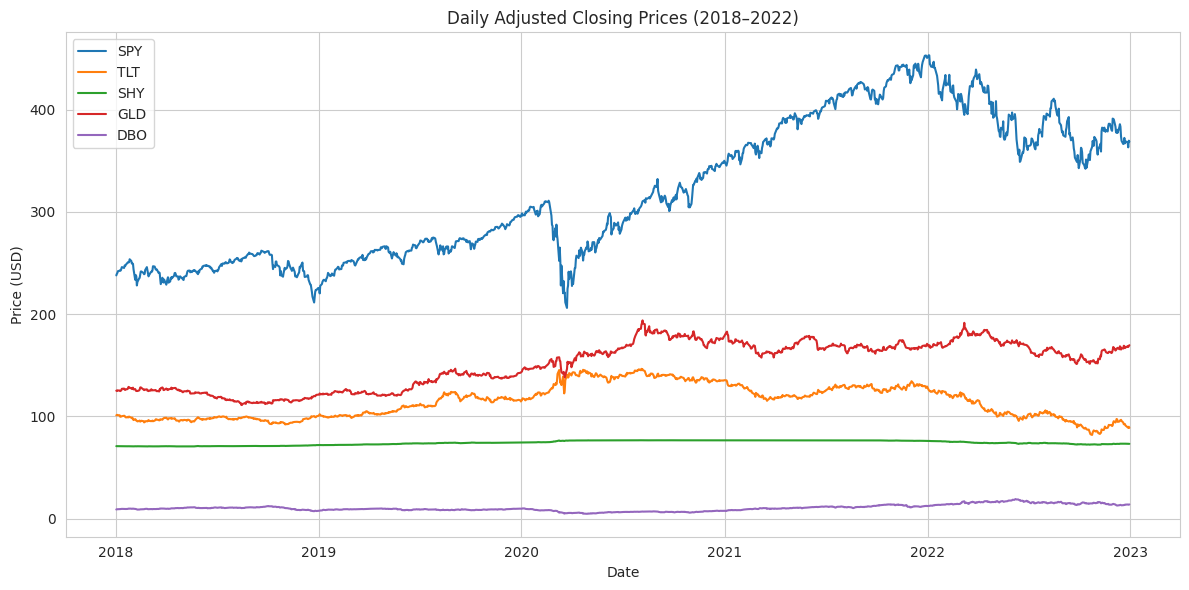

In [6]:
plt.figure(figsize=(12, 6))
for t in tickers:
    plt.plot(prices.index, prices[t], label=t)
plt.title('Daily Adjusted Closing Prices (2018–2022)')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.tight_layout()
plt.show()

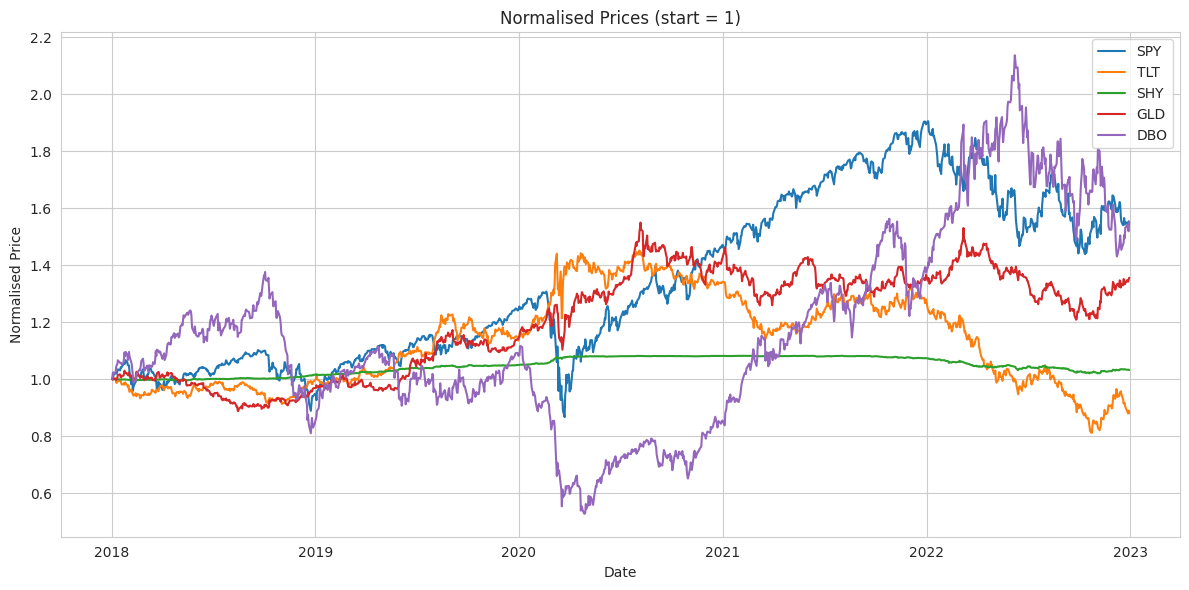

In [7]:
norm_prices = prices / prices.iloc[0]

plt.figure(figsize=(12, 6))
for t in tickers:
    plt.plot(norm_prices.index, norm_prices[t], label=t)
plt.title('Normalised Prices (start = 1)')
plt.xlabel('Date')
plt.ylabel('Normalised Price')
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
returns = prices.pct_change().dropna()
returns.head()

Ticker,DBO,GLD,SHY,SPY,TLT
Date,,,,,
2018-01-03,0.021590,-0.002637,0.000000,0.006325,0.004781
2018-01-04,0.001921,0.005127,-0.000477,0.004215,-0.000159
2018-01-05,-0.004794,-0.001036,0.000000,0.006664,-0.002855
2018-01-08,0.005780,-0.000160,0.000000,0.001829,-0.000637
2018-01-09,0.017241,-0.004628,-0.000358,0.002264,-0.013373


In [9]:
summary = pd.DataFrame(index=[
    'Mean', 'Median', 'StdDev',
    'Skewness', 'Kurtosis',
    'Min', 'Max',
    'ADF_Stat', 'ADF_p'
], columns=tickers)

for t in tickers:
    r = returns[t].dropna()
    adf_stat, adf_p, *_ = adfuller(r)

    summary.loc['Mean', t]      = r.mean()
    summary.loc['Median', t]    = r.median()
    summary.loc['StdDev', t]    = r.std()
    summary.loc['Skewness', t]  = r.skew()
    summary.loc['Kurtosis', t]  = r.kurtosis()
    summary.loc['Min', t]       = r.min()
    summary.loc['Max', t]       = r.max()
    summary.loc['ADF_Stat', t]  = adf_stat
    summary.loc['ADF_p', t]     = adf_p

summary

,SPY,TLT,SHY,GLD,DBO
Mean,0.000441,-0.00005,0.000025,0.000283,0.000587
Median,0.000767,0.000072,0.0,0.00052,0.002442
StdDev,0.013575,0.010171,0.000883,0.009044,0.021621
Skewness,-0.526702,0.253304,0.097192,-0.271012,-0.877983
Kurtosis,10.485334,6.883103,7.495101,3.550753,5.89608
Min,-0.109424,-0.066683,-0.005088,-0.053694,-0.166453
Max,0.090603,0.075195,0.005452,0.04853,0.106227
ADF_Stat,-10.954162,-10.464823,-6.672173,-15.407026,-37.013982
ADF_p,0.0,0.0,0.0,0.0,0.0


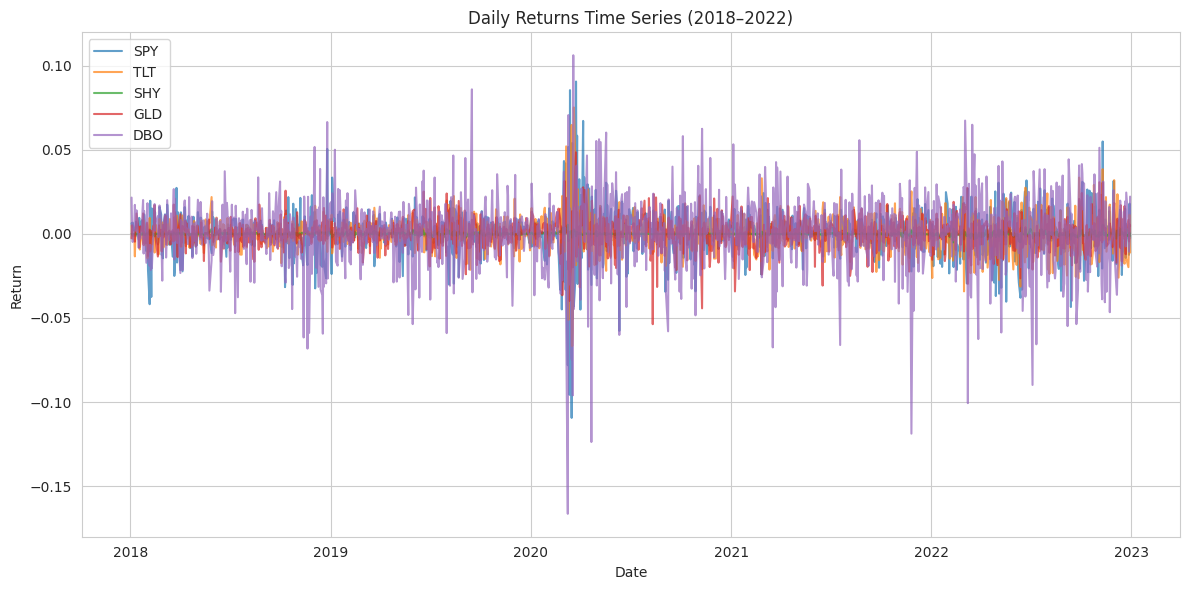

In [10]:
plt.figure(figsize=(12, 6))
for t in tickers:
    plt.plot(returns.index, returns[t], label=t, alpha=0.7)
plt.title('Daily Returns Time Series (2018–2022)')
plt.xlabel('Date')
plt.ylabel('Return')
plt.legend()
plt.tight_layout()
plt.show()

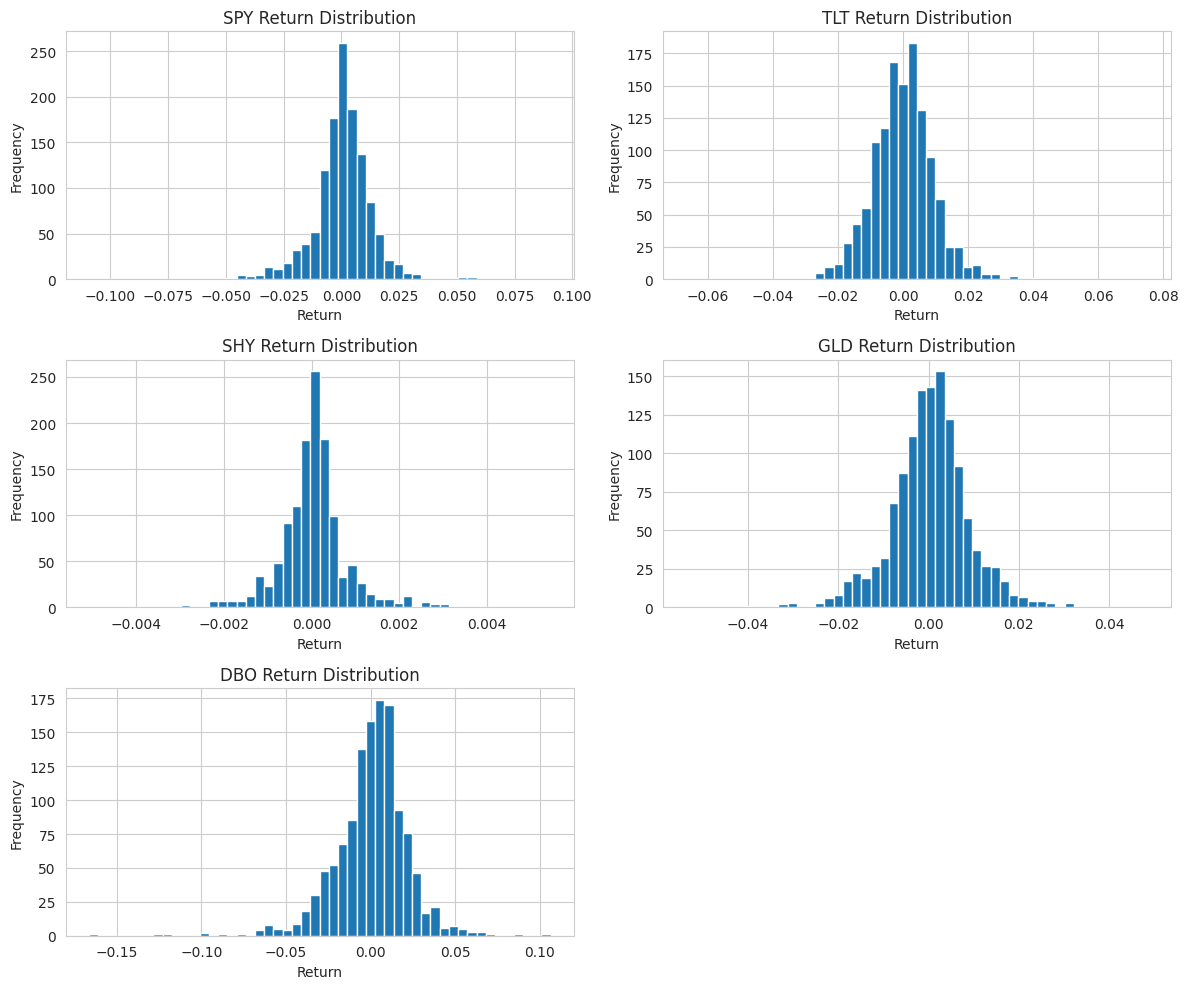

In [11]:
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
axes = axes.flatten()

for i, t in enumerate(tickers):
    ax = axes[i]
    ax.hist(returns[t], bins=50)
    ax.set_title(f'{t} Return Distribution')
    ax.set_xlabel('Return')
    ax.set_ylabel('Frequency')

# Turn off last unused subplot (5 tickers, 6 slots)
axes[-1].axis('off')

plt.tight_layout()
plt.show()

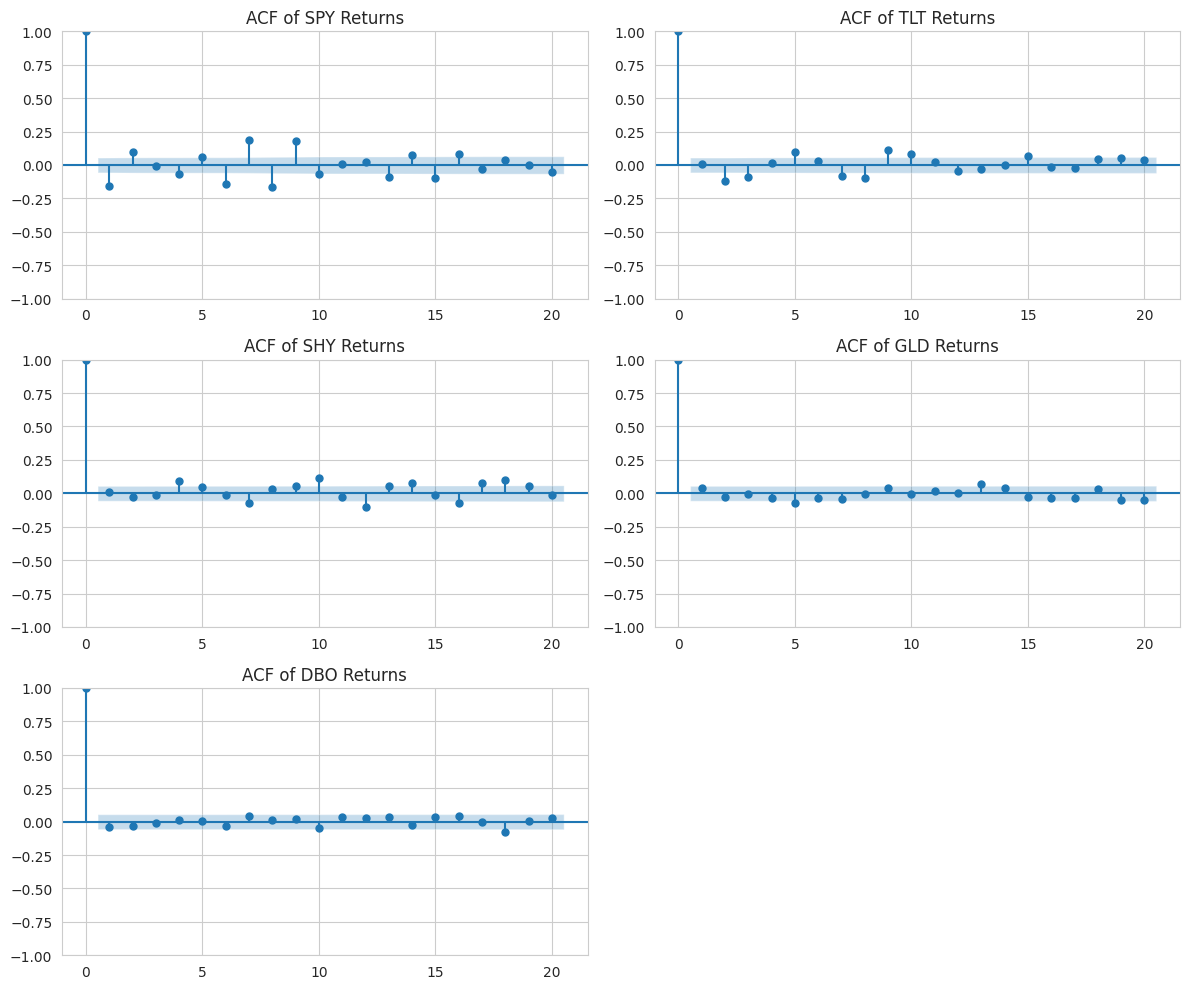

In [12]:
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
axes = axes.flatten()

for i, t in enumerate(tickers):
    plot_acf(returns[t].dropna(), lags=20, ax=axes[i])
    axes[i].set_title(f'ACF of {t} Returns')

axes[-1].axis('off')
plt.tight_layout()
plt.show()

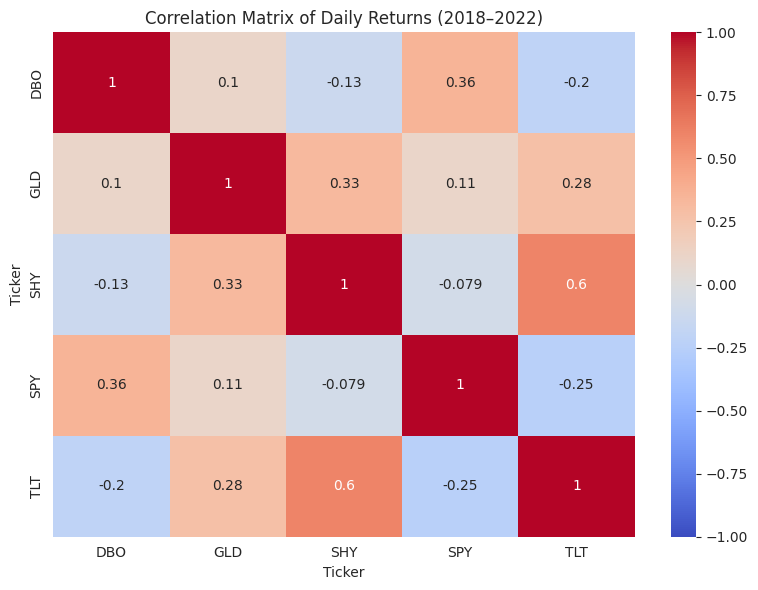

Ticker,DBO,GLD,SHY,SPY,TLT
Ticker,,,,,
DBO,1.000000,0.103214,-0.130173,0.357896,-0.203728
GLD,0.103214,1.000000,0.327873,0.105514,0.279476
SHY,-0.130173,0.327873,1.000000,-0.079347,0.598497
SPY,0.357896,0.105514,-0.079347,1.000000,-0.249392
TLT,-0.203728,0.279476,0.598497,-0.249392,1.000000


In [13]:
corr = returns.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix of Daily Returns (2018–2022)')
plt.tight_layout()
plt.show()

corr

/tmp/ipython-input-270144499.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_returns = returns.resample('M').mean()


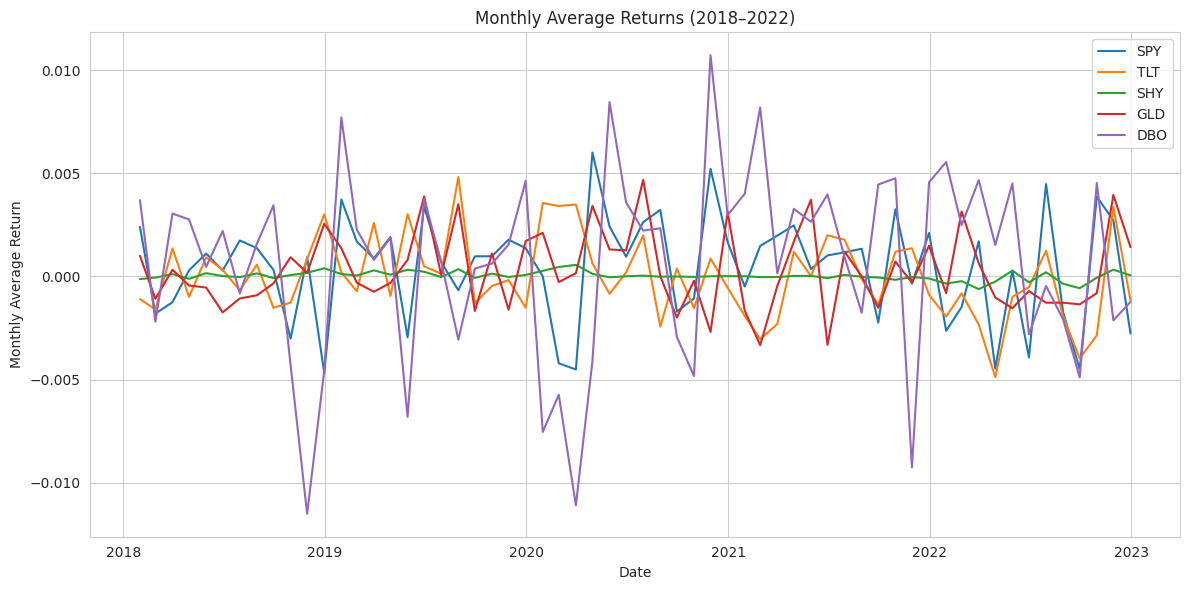

Ticker,DBO,GLD,SHY,SPY,TLT
Date,,,,,
2018-01-31,0.003705,0.001005,-0.000125,0.002402,-0.001097
2018-02-28,-0.002196,-0.001077,-0.000053,-0.001801,-0.001598
2018-03-31,0.003053,0.000324,0.000118,-0.001246,0.001358
2018-04-30,0.002765,-0.000438,-0.000112,0.000301,-0.000988
2018-05-31,0.000465,-0.000535,0.000160,0.001113,0.000927


In [14]:
# Seasonality analysis: Monthly average returns over time
monthly_returns = returns.resample('M').mean()

plt.figure(figsize=(12, 6))
for t in tickers:
    plt.plot(monthly_returns.index, monthly_returns[t], label=t)
plt.title('Monthly Average Returns (2018–2022)')
plt.xlabel('Date')
plt.ylabel('Monthly Average Return')
plt.legend()
plt.tight_layout()
plt.show()

monthly_returns.head()


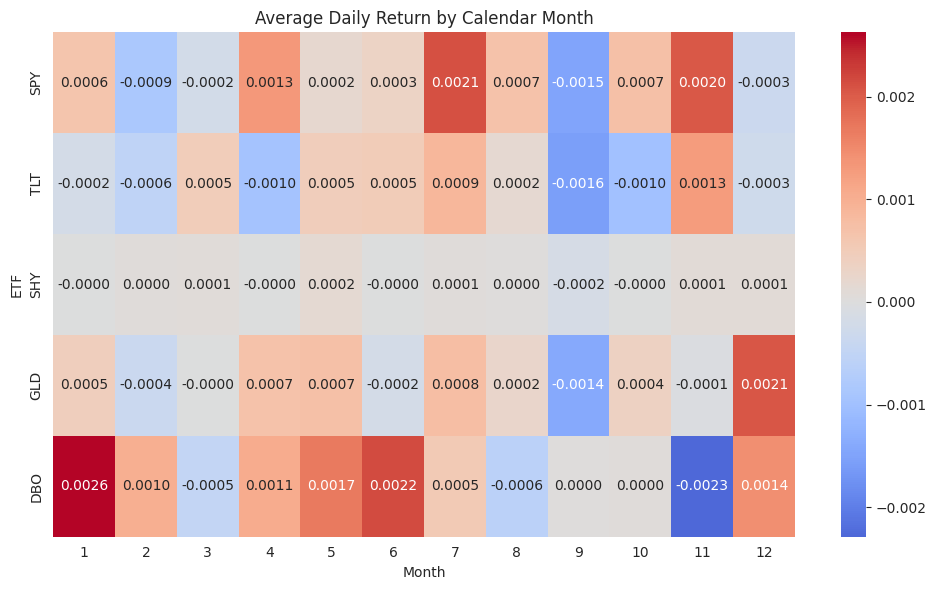

Ticker,SPY,TLT,SHY,GLD,DBO
Month,,,,,
1,0.000640,-0.000181,-0.000009,0.000452,0.002625
2,-0.000864,-0.000550,0.000039,-0.000366,0.001004
3,-0.000200,0.000485,0.000059,-0.000011,-0.000474
4,0.001304,-0.000959,-0.000021,0.000687,0.001063
5,0.000205,0.000473,0.000157,0.000709,0.001690
6,0.000331,0.000510,-0.000022,-0.000178,0.002160
7,0.002116,0.000897,0.000052,0.000774,0.000546
8,0.000671,0.000187,0.000023,0.000246,-0.000616
9,-0.001487,-0.001557,-0.000154,-0.001392,0.000026


In [15]:
# Seasonality analysis: Average return by calendar month (1 = January, ..., 12 = December)
# Group by calendar month
month_mean = returns.groupby(returns.index.month)[tickers].mean()
month_mean.index.name = 'Month'

plt.figure(figsize=(10, 6))
sns.heatmap(month_mean.T, annot=True, fmt='.4f', cmap='coolwarm', center=0)
plt.title('Average Daily Return by Calendar Month')
plt.xlabel('Month')
plt.ylabel('ETF')
plt.tight_layout()
plt.show()

month_mean


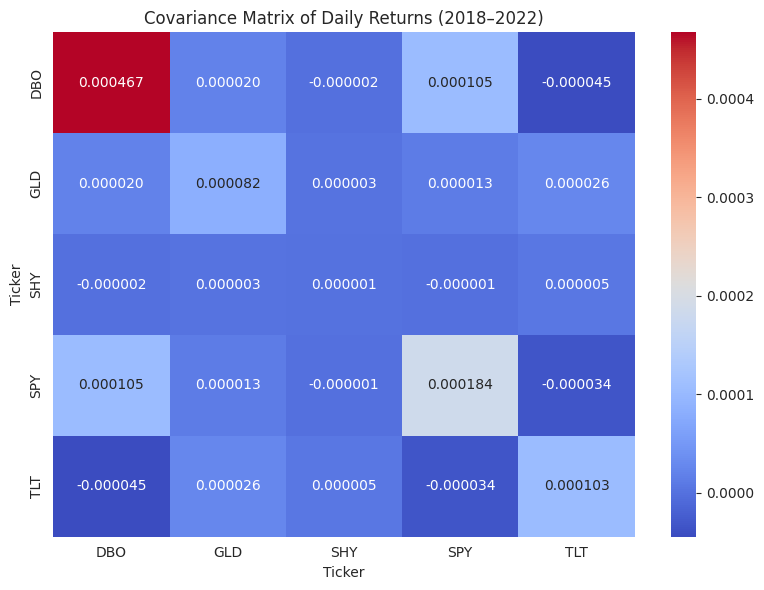

Ticker,DBO,GLD,SHY,SPY,TLT
Ticker,,,,,
DBO,0.000467,0.000020,-2.484041e-06,1.050465e-04,-0.000045
GLD,0.000020,0.000082,2.617044e-06,1.295387e-05,0.000026
SHY,-0.000002,0.000003,7.789563e-07,-9.506624e-07,0.000005
SPY,0.000105,0.000013,-9.506624e-07,1.842824e-04,-0.000034
TLT,-0.000045,0.000026,5.372340e-06,-3.443253e-05,0.000103


In [16]:
# Joint distribution: Covariance matrix of daily returns
cov = returns.cov()

plt.figure(figsize=(8, 6))
sns.heatmap(cov, annot=True, fmt='.6f', cmap='coolwarm')
plt.title('Covariance Matrix of Daily Returns (2018–2022)')
plt.tight_layout()
plt.show()

cov


# Step 2

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_squared_error, mean_absolute_error
import warnings
warnings.filterwarnings('ignore')

### 2a. Create LSTM Models for Each ETF

In [18]:
print("="*60)
print("STEP 2a: CREATING LSTM MODELS FOR EACH ETF")
print("="*60)

# Function to prepare data for LSTM
def prepare_data_for_lstm(returns_series, lookback=60, horizon=25):

    X, y, dates = [], [], []
    data = returns_series.values

    # Calculate future returns: sum of next 'horizon' returns
    future_returns = returns_series.rolling(window=horizon).sum().shift(-horizon)

    # Align data
    for i in range(lookback, len(data) - horizon):
        # Check if we have a valid future return
        if not np.isnan(future_returns.iloc[i]):
            X.append(data[i-lookback:i])
            y.append(future_returns.iloc[i])
            dates.append(returns_series.index[i]) # Append the date

    return np.array(X), np.array(y), pd.to_datetime(dates)

# Function to create LSTM model
def create_lstm_model(input_shape, units=50, dropout_rate=0.2):
    """
    Create LSTM model with specified architecture
    """
    model = Sequential([
        LSTM(units, return_sequences=True, input_shape=input_shape),
        Dropout(dropout_rate),
        LSTM(units, return_sequences=False),
        Dropout(dropout_rate),
        Dense(25, activation='relu'),
        Dense(1)
    ])
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

# Prepare data for each ETF
lookback = 60
horizon = 25

# Dictionary to store models
models = {}
predictions = {}
histories = {}

print("Initializing LSTM models for each ETF...")
print(f"Lookback period: {lookback} days")
print(f"Prediction horizon: {horizon} days")
print(f"ETFs: {tickers}")

# Display data preparation progress
print("\nData Preparation:")
for ticker in tickers:
    try:
        X, y, dates = prepare_data_for_lstm(returns[ticker], lookback, horizon)
        print(f"{ticker}: {X.shape[0]} samples prepared")
    except Exception as e:
        print(f"{ticker}: Error in data preparation - {str(e)}")

STEP 2a: CREATING LSTM MODELS FOR EACH ETF
Initializing LSTM models for each ETF...
Lookback period: 60 days
Prediction horizon: 25 days
ETFs: ['SPY', 'TLT', 'SHY', 'GLD', 'DBO']

Data Preparation:
SPY: 1173 samples prepared
TLT: 1173 samples prepared
SHY: 1173 samples prepared
GLD: 1173 samples prepared
DBO: 1173 samples prepared


### 2b. Train Each Model

In [29]:
for ticker in tickers:  # Loop through each ETF
    print(f"\n=== Processing {ticker} ===")

    # Prepare data (returns X, y, and corresponding dates)
    X, y, dates = prepare_data_for_lstm(returns[ticker], lookback, horizon)

    # Train/test split (80/20)
    split_idx = int(len(X) * 0.8)
    X_train, X_test = X[:split_idx], X[split_idx:]
    y_train, y_test = y[:split_idx], y[split_idx:]
    dates_train, dates_test = dates[:split_idx], dates[split_idx:]

    # Reshape for LSTM [samples, timesteps, features]
    X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
    X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

    # Create model
    model = create_lstm_model((lookback, 1))

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True
    )

    # Train model
    history = model.fit(
        X_train, y_train,
        validation_split=0.2,
        epochs=100,
        batch_size=32,
        callbacks=[early_stop],
        verbose=0
    )

    # Store model & history
    models[ticker] = model
    histories[ticker] = history

    # Predictions
    y_pred_train = model.predict(X_train, verbose=0).flatten()
    y_pred_test = model.predict(X_test, verbose=0).flatten()

    # Metrics
    train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_train))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
    train_mae = mean_absolute_error(y_train, y_pred_train)
    test_mae = mean_absolute_error(y_test, y_pred_test)

    print(f"Train RMSE: {train_rmse:.6f}, Test RMSE: {test_rmse:.6f}")
    print(f"Train MAE: {train_mae:.6f}, Test MAE: {test_mae:.6f}")

    # Store predictions + *correct key name*
    predictions[ticker] = {
        'y_train': y_train,
        'y_test': y_test,
        'y_pred_train': y_pred_train,
        'y_pred_test': y_pred_test,
        'test_dates': dates_test   # ← FIXED KEY
    }


=== Processing SPY ===
Train RMSE: 0.053012, Test RMSE: 0.078531
Train MAE: 0.033613, Test MAE: 0.066987

=== Processing TLT ===
Train RMSE: 0.041614, Test RMSE: 0.071718
Train MAE: 0.031716, Test MAE: 0.062105

=== Processing SHY ===
Train RMSE: 0.004302, Test RMSE: 0.008154
Train MAE: 0.002687, Test MAE: 0.007033

=== Processing GLD ===
Train RMSE: 0.040215, Test RMSE: 0.045671
Train MAE: 0.032017, Test MAE: 0.037405

=== Processing DBO ===
Train RMSE: 0.112104, Test RMSE: 0.097759
Train MAE: 0.082683, Test MAE: 0.079424


### 2c. Test Models and Compare Performance


STEP 2c: TESTING MODELS & COMPARATIVE ANALYSIS

 PERFORMANCE METRICS SUMMARY:
--------------------------------------------------

SPY:
  In-sample R²:   0.1363
  Out-sample R²:  -0.3918
  Out-sample RMSE: 0.078531
  MSE Ratio:       2.19

TLT:
  In-sample R²:   -0.0004
  Out-sample R²:  -0.4329
  Out-sample RMSE: 0.071718
  MSE Ratio:       2.97

SHY:
  In-sample R²:   -0.1673
  Out-sample R²:  -0.3540
  Out-sample RMSE: 0.008154
  MSE Ratio:       3.59

GLD:
  In-sample R²:   -0.0040
  Out-sample R²:  -0.0246
  Out-sample RMSE: 0.045671
  MSE Ratio:       1.29

DBO:
  In-sample R²:   -0.0088
  Out-sample R²:  -0.0245
  Out-sample RMSE: 0.097759
  MSE Ratio:       0.76

COMPREHENSIVE PERFORMANCE COMPARISON
     Train_RMSE  Test_RMSE  Train_MAE  Test_MAE  Train_R2   Test_R2  MSE_Ratio  Test_R2_Rank  Test_RMSE_Rank
SPY    0.053012   0.078531   0.033613  0.066987  0.136323 -0.391848   2.194512           4.0             4.0
TLT    0.041614   0.071718   0.031716  0.062105 -0.000403 -0.4329

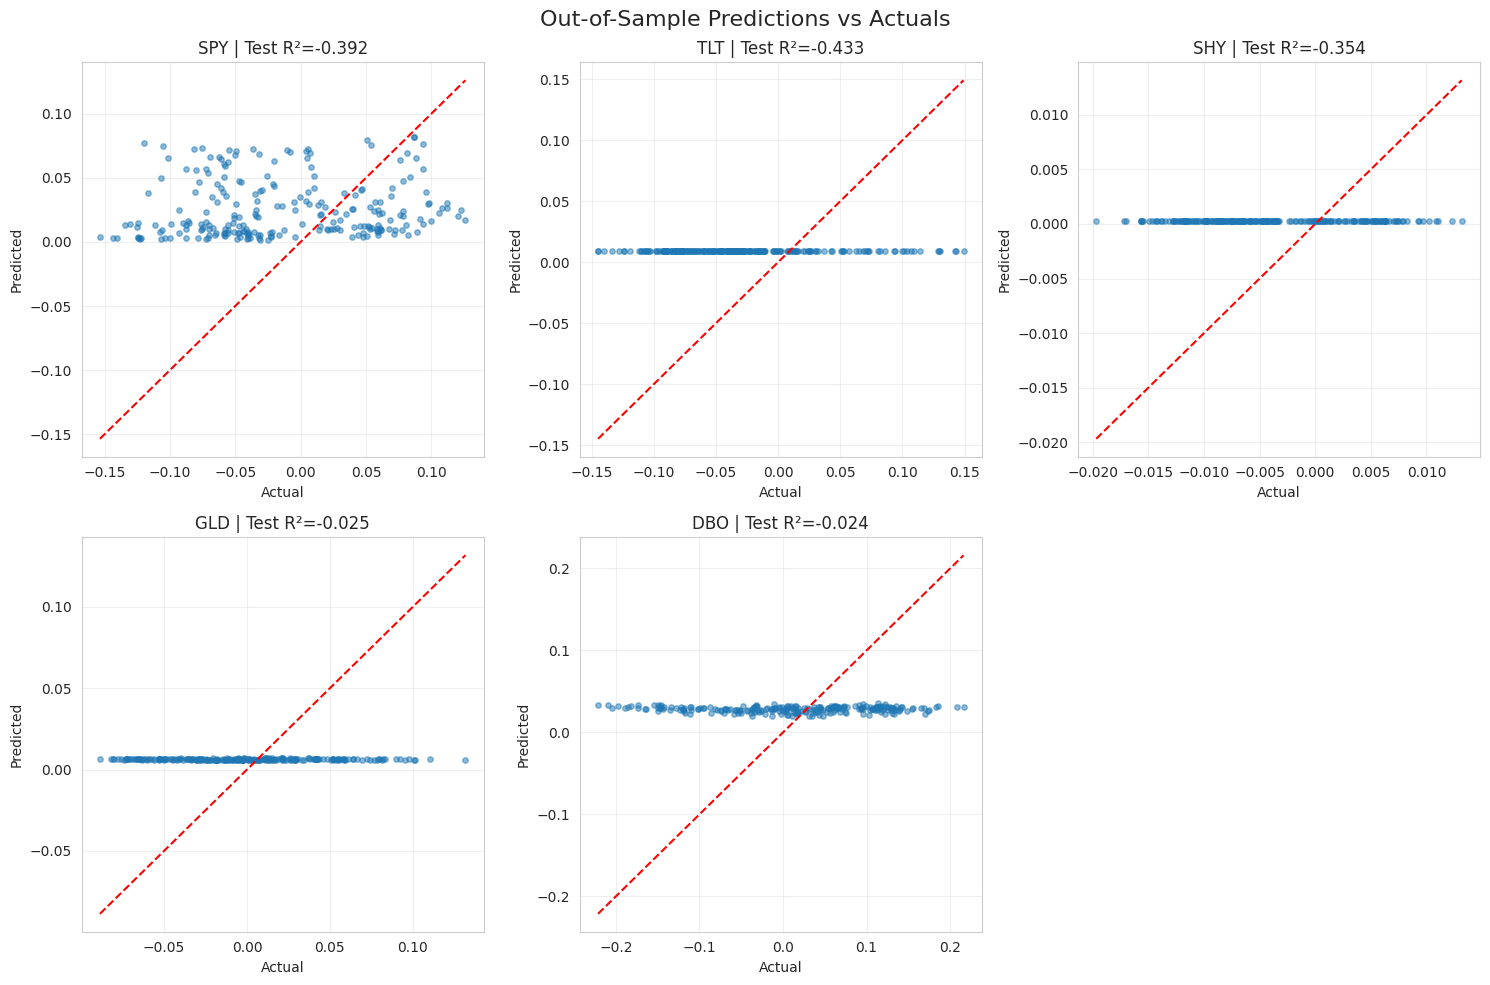


STEP 2c COMPLETED SUCCESSFULLY


In [30]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

def safe_r2(y_true, y_pred):
    """Avoid R² errors when test sample is too small."""
    if len(y_true) < 2:
        return np.nan
    return r2_score(y_true, y_pred)

print("\n" + "="*60)
print("STEP 2c: TESTING MODELS & COMPARATIVE ANALYSIS")
print("="*60)

performance_metrics = {}

print("\n PERFORMANCE METRICS SUMMARY:")
print("-"*50)

# Loop over predictions (correct)
for ticker, preds in predictions.items():

    # Ensure everything is numpy arrays
    y_train = np.array(preds['y_train'])
    y_test  = np.array(preds['y_test'])
    y_pred_train = np.array(preds['y_pred_train'])
    y_pred_test  = np.array(preds['y_pred_test'])

    # Compute metrics
    mse_train = mean_squared_error(y_train, y_pred_train)
    mse_test  = mean_squared_error(y_test, y_pred_test)

    performance_metrics[ticker] = {
        'Train_RMSE': np.sqrt(mse_train),
        'Test_RMSE': np.sqrt(mse_test),
        'Train_MAE': mean_absolute_error(y_train, y_pred_train),
        'Test_MAE': mean_absolute_error(y_test, y_pred_test),
        'Train_R2': safe_r2(y_train, y_pred_train),
        'Test_R2': safe_r2(y_test, y_pred_test),
        'MSE_Ratio': mse_test / mse_train if mse_train > 0 else np.inf
    }

    print(f"\n{ticker}:")
    print(f"  In-sample R²:   {performance_metrics[ticker]['Train_R2']:.4f}")
    print(f"  Out-sample R²:  {performance_metrics[ticker]['Test_R2']:.4f}")
    print(f"  Out-sample RMSE: {performance_metrics[ticker]['Test_RMSE']:.6f}")
    print(f"  MSE Ratio:       {performance_metrics[ticker]['MSE_Ratio']:.2f}")

# Stop if empty
if not performance_metrics:
    print("No predictions found — check previous steps.")
    raise SystemExit()

# Convert to dataframe
performance_df = pd.DataFrame(performance_metrics).T.round(6)

# Rankings
performance_df['Test_R2_Rank'] = performance_df['Test_R2'].rank(ascending=False)
performance_df['Test_RMSE_Rank'] = performance_df['Test_RMSE'].rank(ascending=True)

print("\n" + "="*60)
print("COMPREHENSIVE PERFORMANCE COMPARISON")
print("="*60)
print(performance_df.to_string())

# =================================================
# VISUALIZATIONS (CLEAN & SAFE)
# =================================================

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, (ticker, preds) in enumerate(predictions.items()):
    ax = axes[i]

    y_test = np.array(preds['y_test'])
    y_pred_test = np.array(preds['y_pred_test'])

    ax.scatter(y_test, y_pred_test, alpha=0.5, s=15)

    min_val = min(y_test.min(), y_pred_test.min())
    max_val = max(y_test.max(), y_pred_test.max())
    ax.plot([min_val, max_val], [min_val, max_val], 'r--')

    ax.set_title(f"{ticker} | Test R²={performance_df.loc[ticker,'Test_R2']:.3f}")
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")
    ax.grid(alpha=0.3)

# Hide unused subplots
for j in range(len(predictions), 6):
    axes[j].axis('off')

plt.suptitle('Out-of-Sample Predictions vs Actuals', fontsize=16)
plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("STEP 2c COMPLETED SUCCESSFULLY")
print("="*60)

### 2d. Create Trading Strategy

In [31]:
print("\n" + "="*60)
print("STEP 2d: CREATING TRADING STRATEGY (CORRECTED)")
print("="*60)

def create_trading_strategy(predictions_dict, returns_data, horizon=25, long_n=2, short_n=2):

    # -----------------------------------------
    # 1. Build aligned prediction DataFrame
    # -----------------------------------------
    pred_frames = []

    for t, pred_obj in predictions_dict.items():
        y_pred = np.array(pred_obj["y_pred_test"])
        y_dates = np.array(pred_obj["test_dates"])  # FIXED: Changed 'y_test_dates' to 'test_dates'

        if len(y_pred) != len(y_dates):
            print(f"WARNING: Length mismatch for {t}. Skipping.")
            continue

        df_tmp = pd.DataFrame({
            "Prediction": y_pred,
            "Ticker": t
        }, index=pd.to_datetime(y_dates))

        pred_frames.append(df_tmp)

    if len(pred_frames) == 0:
        print("No valid predictions found.")
        return None, None, None

    pred_all = pd.concat(pred_frames)
    pred_df = pred_all.pivot_table(values="Prediction", index=pred_all.index, columns="Ticker")
    pred_df = pred_df.sort_index()

    print(f"Predictions aligned: {pred_df.shape}")

    tickers = list(pred_df.columns)

    # -----------------------------------------
    # 2. Rebalancing dates
    # -----------------------------------------
    rebalance_dates = pred_df.index[::horizon]
    print(f"Rebalancing events: {len(rebalance_dates)}")

    # -----------------------------------------
    # 3. Actual forward returns from returns
    # -----------------------------------------
    prices = (1 + returns_data[tickers]).cumprod()

    actual_forward = prices.shift(-horizon) / prices - 1
    actual_forward = actual_forward.reindex(pred_df.index, method="nearest")

    # -----------------------------------------
    # 4. Initialize portfolio weights matrix
    # -----------------------------------------
    portfolio_weights = pd.DataFrame(0.0, index=pred_df.index, columns=tickers)
    trades = []

    # -----------------------------------------
    # 5. Create long/short signals at each rebalance
    # -----------------------------------------
    for i in range(len(rebalance_dates) - 1):

        d = rebalance_dates[i]
        next_d = rebalance_dates[i + 1]

        if d not in pred_df.index:
            continue

        preds = pred_df.loc[d].dropna()
        ranked = preds.sort_values(ascending=False)

        if len(ranked) < 4:
            continue

        long_assets  = ranked.index[:long_n]
        short_assets = ranked.index[-short_n:]

        w_long  = 1 / long_n  if long_n  > 0 else 0
        w_short = -1 / short_n if short_n > 0 else 0

        mask = (pred_df.index >= d) & (pred_df.index < next_d)

        for a in long_assets:
            portfolio_weights.loc[mask, a] = w_long
        for a in short_assets:
            portfolio_weights.loc[mask, a] = w_short

        trades.append({
            "Date": d,
            "Long": list(long_assets),
            "Short": list(short_assets),
        })

    # -----------------------------------------
    # 6. Strategy returns
    # -----------------------------------------
    strategy_returns = (portfolio_weights * actual_forward).sum(axis=1)
    strategy_returns = strategy_returns.dropna()

    print(f"Strategy trading days: {len(strategy_returns)}")
    print(f"Average daily return: {strategy_returns.mean():.6f}")

    return strategy_returns, portfolio_weights, trades


# RUN STRATEGY
portfolio_returns, positions, trade_log = create_trading_strategy(
    predictions_dict = predictions,
    returns_data = returns,
    horizon = 25,
    long_n = 2,
    short_n = 2
)


STEP 2d: CREATING TRADING STRATEGY (CORRECTED)
Predictions aligned: (235, 5)
Rebalancing events: 10
Strategy trading days: 235
Average daily return: 0.003821


### 2e. Backtest Strategy


STEP 2e: BACKTESTING STRATEGY

Running backtest analysis...
----------------------------------------
Starting backtest analysis...

Calculating benchmarks...
  Calculating equally weighted benchmark...
  Comparison period: 2021-12-20 00:00:00 to 2022-11-23 00:00:00
  Days in comparison: 235

PERFORMANCE METRICS COMPARISON

 Performance Comparison Table:
--------------------------------------------------------------------------------
Strategy           LSTM Strategy  Equal Weight B&H
Total Return              0.8628           -0.0573
Annual Return             0.9485           -0.0613
Annual Volatility         0.7683            0.1246
Sharpe Ratio              1.2085           -0.6527
Sortino Ratio             1.9635           -1.0033
Max Drawdown             -0.8648           -0.1563
Win Rate                  0.5064            0.4766
Profit Factor             1.2197            0.9290
Calmar Ratio              1.0968           -0.3922
Total Days              235.0000          235.0000



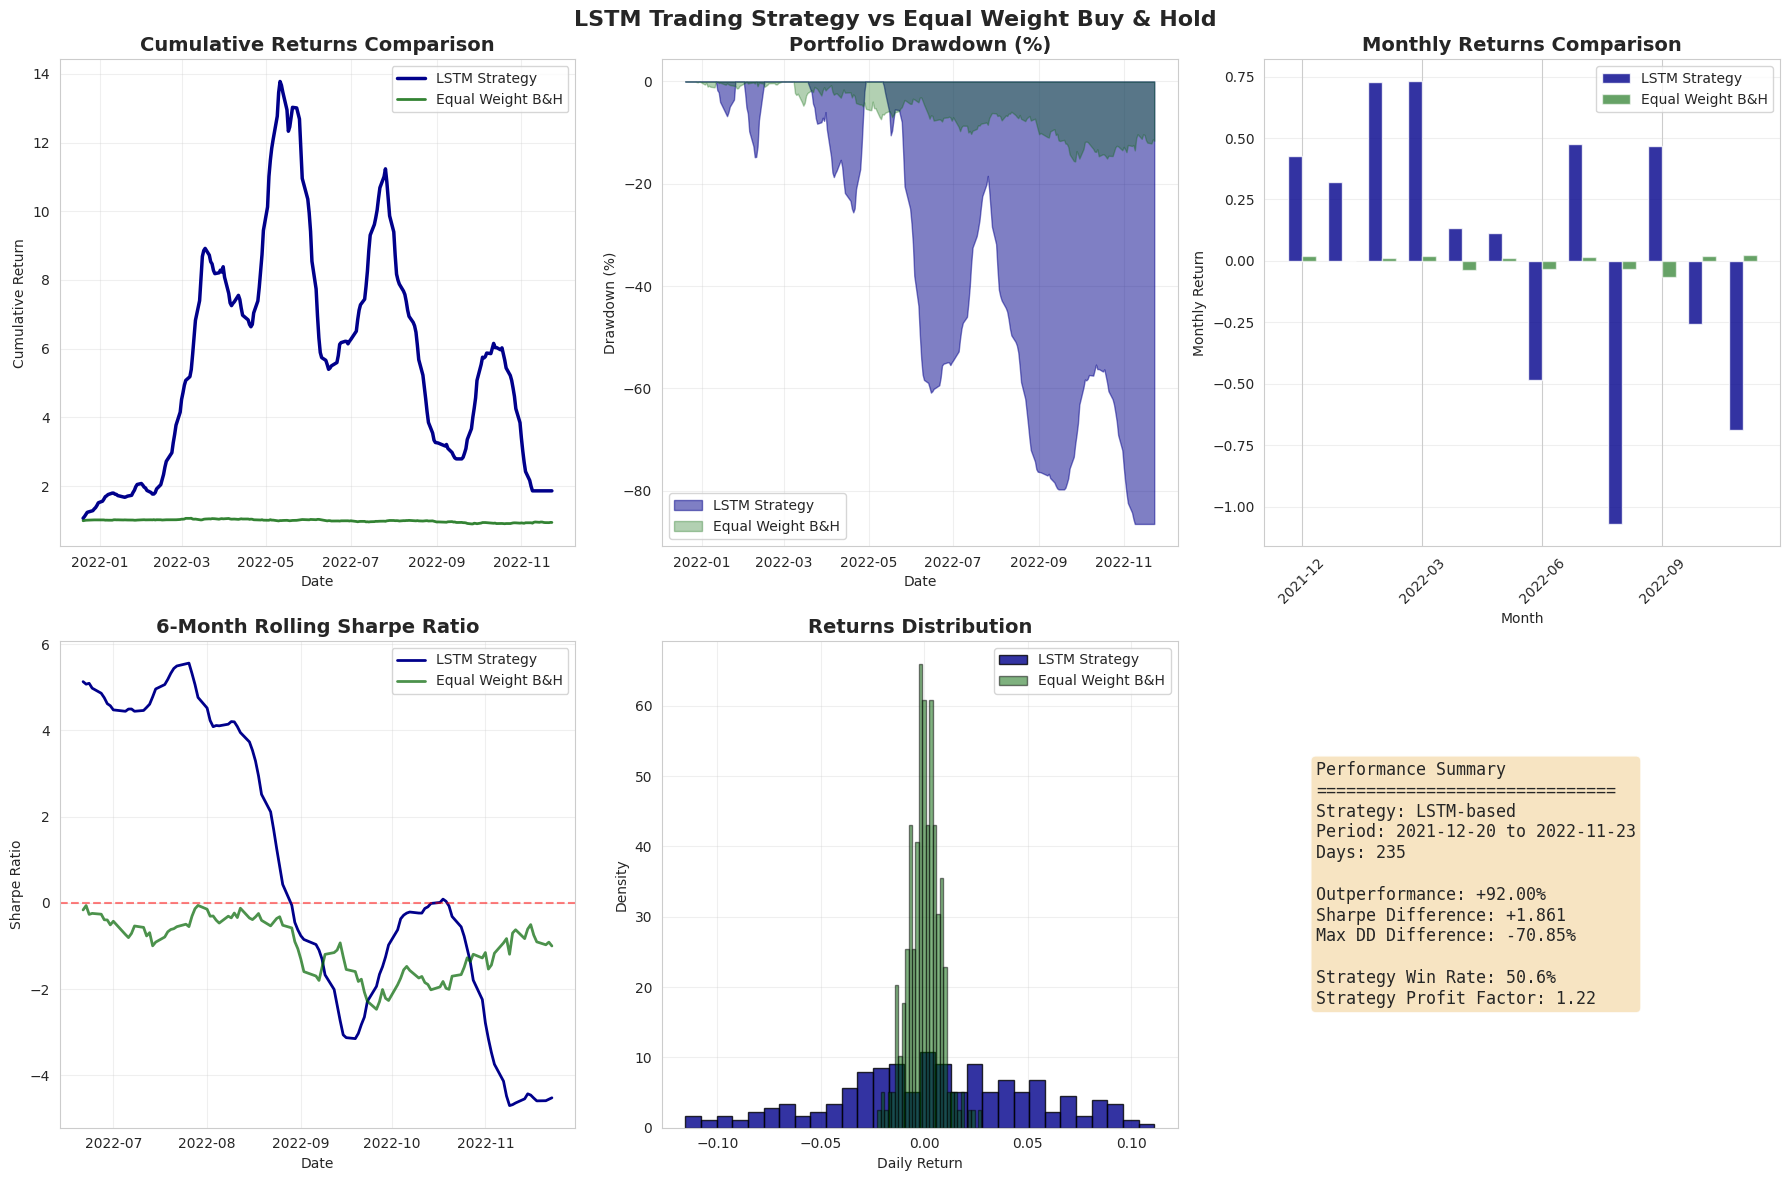


CONCLUSION
 The LSTM-based strategy OUTPERFORMED the benchmark by 92.00%
 Better risk-adjusted returns (Sharpe ratio higher by 1.861)
 Lower maximum drawdown (-86.48% vs -15.63%)

 PRACTICAL CONSIDERATIONS:
   • Transaction costs are not included in this analysis
   • Slippage and market impact are not accounted for
   • Rebalancing occurs every 25 days (approximately monthly)
   • Short selling is assumed to be feasible
   • Predictions are based on historical data only

BACKTEST COMPLETED SUCCESSFULLY

STEP 2e COMPLETED


In [32]:
print("\n" + "="*60)
print("STEP 2e: BACKTESTING STRATEGY")
print("="*60)

def backtest_strategy(portfolio_returns, positions, returns_data, tickers):

    if portfolio_returns is None or len(portfolio_returns) == 0:
        print(" No portfolio returns to backtest")
        return None

    print("Starting backtest analysis...")

    # Calculate buy-and-hold benchmark (equally weighted portfolio)
    def calculate_equally_weighted_portfolio(returns_df, tickers_list):
        """Calculate returns of equally weighted portfolio (rebalanced monthly)"""
        print("  Calculating equally weighted benchmark...")

        # Create equally weighted portfolio with monthly rebalancing
        weights = pd.DataFrame(1.0/len(tickers_list),
                              index=returns_df.index,
                              columns=tickers_list)

        # Rebalance every 25 days (approximately monthly)
        portfolio = pd.Series(0.0, index=returns_df.index)

        for i in range(0, len(returns_df), 25):
            start_idx = i
            end_idx = min(i + 25, len(returns_df))

            for ticker in tickers_list:
                if ticker in returns_df.columns:
                    portfolio.iloc[start_idx:end_idx] += weights[ticker].iloc[start_idx] * returns_df[ticker].iloc[start_idx:end_idx]

        return portfolio

    # Calculate benchmarks
    print("\nCalculating benchmarks...")

    # 1. Equal weight buy-and-hold (rebalanced every 25 days)
    benchmark_ew = calculate_equally_weighted_portfolio(returns, tickers)

    # Align all series
    common_dates = portfolio_returns.index.intersection(benchmark_ew.index)

    if len(common_dates) == 0:
        print(" No common dates for comparison")
        return None

    strategy_aligned = portfolio_returns.reindex(common_dates).fillna(0)
    benchmark_aligned = benchmark_ew.reindex(common_dates).fillna(0)

    print(f"  Comparison period: {common_dates[0]} to {common_dates[-1]}")
    print(f"  Days in comparison: {len(common_dates)}")

    # Calculate cumulative returns
    strategy_cumulative = (1 + strategy_aligned).cumprod()
    benchmark_cumulative = (1 + benchmark_aligned).cumprod()

    # Performance metrics function
    def calculate_performance_metrics(returns_series, name="Strategy", risk_free_rate=0.02):
        """Calculate comprehensive performance metrics"""
        if len(returns_series) == 0:
            return {}

        # Basic metrics
        total_return = (1 + returns_series).prod() - 1
        total_days = len(returns_series)
        total_years = total_days / 252

        annual_return = (1 + total_return) ** (1/total_years) - 1 if total_years > 0 else 0
        annual_volatility = returns_series.std() * np.sqrt(252)

        # Risk-adjusted metrics
        sharpe_ratio = (annual_return - risk_free_rate) / annual_volatility if annual_volatility > 0 else 0

        # Maximum drawdown
        cumulative = (1 + returns_series).cumprod()
        running_max = cumulative.expanding().max()
        drawdown = (cumulative - running_max) / running_max
        max_drawdown = drawdown.min()

        # Sortino ratio (only downside deviation)
        downside_returns = returns_series[returns_series < 0]
        downside_deviation = downside_returns.std() * np.sqrt(252) if len(downside_returns) > 0 else 0
        sortino_ratio = (annual_return - risk_free_rate) / downside_deviation if downside_deviation > 0 else 0

        # Win rate
        positive_trades = (returns_series > 0).sum()
        win_rate = positive_trades / len(returns_series) if len(returns_series) > 0 else 0

        # Profit factor
        gross_profit = returns_series[returns_series > 0].sum()
        gross_loss = abs(returns_series[returns_series < 0].sum())
        profit_factor = gross_profit / gross_loss if gross_loss > 0 else float('inf')

        # Calmar ratio
        calmar_ratio = annual_return / abs(max_drawdown) if max_drawdown != 0 else float('inf')

        return {
            'Strategy': name,
            'Total Return': total_return,
            'Annual Return': annual_return,
            'Annual Volatility': annual_volatility,
            'Sharpe Ratio': sharpe_ratio,
            'Sortino Ratio': sortino_ratio,
            'Max Drawdown': max_drawdown,
            'Win Rate': win_rate,
            'Profit Factor': profit_factor,
            'Calmar Ratio': calmar_ratio,
            'Total Days': total_days
        }

    # Calculate metrics
    print("\n" + "="*60)
    print("PERFORMANCE METRICS COMPARISON")
    print("="*60)

    strategy_metrics = calculate_performance_metrics(strategy_aligned, "LSTM Strategy")
    benchmark_metrics = calculate_performance_metrics(benchmark_aligned, "Equal Weight B&H")

    # Create comparison dataframe
    comparison_df = pd.DataFrame([strategy_metrics, benchmark_metrics])
    comparison_df.set_index('Strategy', inplace=True)

    print("\n Performance Comparison Table:")
    print("-"*80)
    print(comparison_df.T.round(4).to_string())

    # Calculate outperformance
    outperformance = strategy_metrics['Total Return'] - benchmark_metrics['Total Return']
    sharpe_diff = strategy_metrics['Sharpe Ratio'] - benchmark_metrics['Sharpe Ratio']

    print("\n" + "="*60)
    print("PERFORMANCE ANALYSIS")
    print("="*60)

    print(f"\n1. ABSOLUTE PERFORMANCE:")
    print(f"   • Strategy Total Return: {strategy_metrics['Total Return']:.2%}")
    print(f"   • Benchmark Total Return: {benchmark_metrics['Total Return']:.2%}")
    print(f"   • Outperformance: {outperformance:.2%}")

    print(f"\n2. RISK-ADJUSTED PERFORMANCE:")
    print(f"   • Strategy Sharpe Ratio: {strategy_metrics['Sharpe Ratio']:.3f}")
    print(f"   • Benchmark Sharpe Ratio: {benchmark_metrics['Sharpe Ratio']:.3f}")
    print(f"   • Sharpe Difference: {sharpe_diff:.3f}")

    print(f"\n3. RISK METRICS:")
    print(f"   • Strategy Volatility: {strategy_metrics['Annual Volatility']:.2%}")
    print(f"   • Benchmark Volatility: {benchmark_metrics['Annual Volatility']:.2%}")
    print(f"   • Strategy Max Drawdown: {strategy_metrics['Max Drawdown']:.2%}")
    print(f"   • Benchmark Max Drawdown: {benchmark_metrics['Max Drawdown']:.2%}")

    print(f"\n4. TRADING CHARACTERISTICS:")
    print(f"   • Strategy Win Rate: {strategy_metrics['Win Rate']:.1%}")
    print(f"   • Strategy Profit Factor: {strategy_metrics['Profit Factor']:.2f}")

    # Visualization
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))

    # Plot 1: Cumulative returns comparison
    axes[0, 0].plot(strategy_cumulative.index, strategy_cumulative.values,
                   label='LSTM Strategy', linewidth=2.5, color='darkblue')
    axes[0, 0].plot(benchmark_cumulative.index, benchmark_cumulative.values,
                   label='Equal Weight B&H', linewidth=2, color='darkgreen', alpha=0.8)
    axes[0, 0].set_title('Cumulative Returns Comparison', fontsize=14, fontweight='bold')
    axes[0, 0].set_xlabel('Date')
    axes[0, 0].set_ylabel('Cumulative Return')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)

    # Plot 2: Drawdown comparison
    drawdown_strategy = (strategy_cumulative / strategy_cumulative.expanding().max() - 1) * 100
    drawdown_benchmark = (benchmark_cumulative / benchmark_cumulative.expanding().max() - 1) * 100

    axes[0, 1].fill_between(drawdown_strategy.index, 0, drawdown_strategy.values,
                           alpha=0.5, label='LSTM Strategy', color='darkblue')
    axes[0, 1].fill_between(drawdown_benchmark.index, 0, drawdown_benchmark.values,
                           alpha=0.3, label='Equal Weight B&H', color='darkgreen')
    axes[0, 1].set_title('Portfolio Drawdown (%)', fontsize=14, fontweight='bold')
    axes[0, 1].set_xlabel('Date')
    axes[0, 1].set_ylabel('Drawdown (%)')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)

    # Plot 3: Monthly returns comparison
    monthly_strategy = strategy_aligned.resample('M').sum()
    monthly_benchmark = benchmark_aligned.resample('M').sum()

    x = range(len(monthly_strategy))
    width = 0.35

    axes[0, 2].bar([i - width/2 for i in x], monthly_strategy.values, width,
                  label='LSTM Strategy', alpha=0.8, color='darkblue')
    axes[0, 2].bar([i + width/2 for i in x], monthly_benchmark.values, width,
                  label='Equal Weight B&H', alpha=0.6, color='darkgreen')
    axes[0, 2].set_title('Monthly Returns Comparison', fontsize=14, fontweight='bold')
    axes[0, 2].set_xlabel('Month')
    axes[0, 2].set_ylabel('Monthly Return')
    axes[0, 2].set_xticks(x[::3])
    axes[0, 2].set_xticklabels([d.strftime('%Y-%m') for d in monthly_strategy.index[::3]], rotation=45)
    axes[0, 2].legend()
    axes[0, 2].grid(True, alpha=0.3, axis='y')

    # Plot 4: Rolling Sharpe ratio (6-month window)
    def rolling_sharpe(returns_series, window=126):
        rolling_mean = returns_series.rolling(window).mean() * 252
        rolling_std = returns_series.rolling(window).std() * np.sqrt(252)
        return rolling_mean / rolling_std

    rolling_window = 126  # Approximately 6 months
    rolling_sharpe_strategy = rolling_sharpe(strategy_aligned, rolling_window)
    rolling_sharpe_benchmark = rolling_sharpe(benchmark_aligned, rolling_window)

    axes[1, 0].plot(rolling_sharpe_strategy.index, rolling_sharpe_strategy.values,
                   label='LSTM Strategy', linewidth=2, color='darkblue')
    axes[1, 0].plot(rolling_sharpe_benchmark.index, rolling_sharpe_benchmark.values,
                   label='Equal Weight B&H', linewidth=2, color='darkgreen', alpha=0.7)
    axes[1, 0].set_title('6-Month Rolling Sharpe Ratio', fontsize=14, fontweight='bold')
    axes[1, 0].set_xlabel('Date')
    axes[1, 0].set_ylabel('Sharpe Ratio')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
    axes[1, 0].axhline(y=0, color='r', linestyle='--', alpha=0.5)

    # Plot 5: Returns distribution
    axes[1, 1].hist(strategy_aligned, bins=30, alpha=0.8, label='LSTM Strategy',
                   color='darkblue', density=True, edgecolor='black')
    axes[1, 1].hist(benchmark_aligned, bins=30, alpha=0.5, label='Equal Weight B&H',
                   color='darkgreen', density=True, edgecolor='black')
    axes[1, 1].set_title('Returns Distribution', fontsize=14, fontweight='bold')
    axes[1, 1].set_xlabel('Daily Return')
    axes[1, 1].set_ylabel('Density')
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)

    # Plot 6: Performance summary (text)
    axes[1, 2].axis('off')
    summary_text = (
        f"Performance Summary\n"
        f"{'='*30}\n"
        f"Strategy: LSTM-based\n"
        f"Period: {common_dates[0].strftime('%Y-%m-%d')} to {common_dates[-1].strftime('%Y-%m-%d')}\n"
        f"Days: {len(common_dates)}\n"
        f"\n"
        f"Outperformance: {outperformance:+.2%}\n"
        f"Sharpe Difference: {sharpe_diff:+.3f}\n"
        f"Max DD Difference: {(strategy_metrics['Max Drawdown'] - benchmark_metrics['Max Drawdown']):+.2%}\n"
        f"\n"
        f"Strategy Win Rate: {strategy_metrics['Win Rate']:.1%}\n"
        f"Strategy Profit Factor: {strategy_metrics['Profit Factor']:.2f}"
    )

    axes[1, 2].text(0.1, 0.5, summary_text, fontsize=12, fontfamily='monospace',
                   verticalalignment='center', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

    plt.suptitle('LSTM Trading Strategy vs Equal Weight Buy & Hold', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # Final conclusion
    print("\n" + "="*60)
    print("CONCLUSION")
    print("="*60)

    if outperformance > 0:
        print(f" The LSTM-based strategy OUTPERFORMED the benchmark by {outperformance:.2%}")
    else:
        print(f" The LSTM-based strategy UNDERPERFORMED the benchmark by {abs(outperformance):.2%}")

    if sharpe_diff > 0:
        print(f" Better risk-adjusted returns (Sharpe ratio higher by {sharpe_diff:.3f})")
    else:
        print(f" Worse risk-adjusted returns (Sharpe ratio lower by {abs(sharpe_diff):.3f})")

    if strategy_metrics['Max Drawdown'] < benchmark_metrics['Max Drawdown']:
        print(f" Lower maximum drawdown ({strategy_metrics['Max Drawdown']:.2%} vs {benchmark_metrics['Max Drawdown']:.2%})")
    else:
        print(f" Higher maximum drawdown ({strategy_metrics['Max Drawdown']:.2%} vs {benchmark_metrics['Max Drawdown']:.2%})")

    print(f"\n PRACTICAL CONSIDERATIONS:")
    print("   • Transaction costs are not included in this analysis")
    print("   • Slippage and market impact are not accounted for")
    print("   • Rebalancing occurs every 25 days (approximately monthly)")
    print("   • Short selling is assumed to be feasible")
    print("   • Predictions are based on historical data only")

    return comparison_df

# Run backtest
print("\nRunning backtest analysis...")
print("-"*40)

if 'portfolio_returns' in locals() and portfolio_returns is not None:
    comparison_results = backtest_strategy(portfolio_returns, positions, returns, tickers)

    if comparison_results is not None:
        print("\n" + "="*60)
        print("BACKTEST COMPLETED SUCCESSFULLY")
        print("="*60)
    else:
        print("\n Backtest failed")
else:
    print(" Cannot run backtest - portfolio returns not available")

print(f"\n{'='*60}")
print("STEP 2e COMPLETED")
print(f"{'='*60}")

# Step 3


In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

print("\n" + "="*60)
print("STEP 3: MULTI-OUTPUT LSTM MODEL")
print("="*60)



STEP 3: MULTI-OUTPUT LSTM MODEL


## 3.a

In [34]:
# ==============================================================================
# 3a. Multi-Output Data Preparation
# ==============================================================================
def prepare_data_multi_output(returns_df, lookback, horizon, tickers):
    """
    Prepares data for a multi-output LSTM model.
    X: [samples, lookback, n_assets] - joint historical returns.
    y: [samples, n_assets] - future horizon returns for all assets.
    """
    X, y, dates = [], [], []

    # Calculate future returns (Y) for ALL assets: sum of next 'horizon' returns
    # This aligns the target for every asset at every time step
    future_returns = returns_df[tickers].rolling(window=horizon).sum().shift(-horizon)

    data = returns_df[tickers].values
    future_returns_values = future_returns.values

    # Create sequences
    for i in range(lookback, len(data) - horizon):
        # Ensure we don't have NaNs in the target row
        if not np.isnan(future_returns_values[i]).any():
            X.append(data[i-lookback:i, :])       # History of all assets
            y.append(future_returns_values[i, :]) # Target for all assets
            dates.append(returns_df.index[i])

    return np.array(X), np.array(y), pd.to_datetime(dates)

print("Preparing multi-output data...")
X_multi, y_multi, dates_multi = prepare_data_multi_output(returns, lookback, horizon, tickers)
print(f"Input shape (X): {X_multi.shape}")
print(f"Output shape (y): {y_multi.shape}")


Preparing multi-output data...
Input shape (X): (1173, 60, 5)
Output shape (y): (1173, 5)


## 3.b

In [35]:
# ==============================================================================
# 3b. Train/Test Split and Scaling
# ==============================================================================
# Split (80/20)
split_idx = int(len(X_multi) * 0.8)
X_train_multi, X_test_multi = X_multi[:split_idx], X_multi[split_idx:]
y_train_multi, y_test_multi = y_multi[:split_idx], y_multi[split_idx:]
dates_test_multi = dates_multi[split_idx:]

# Scale Inputs (X)
# Reshape to 2D for scaler: (samples * lookback, n_assets)
scaler_X = StandardScaler()
X_train_reshaped = X_train_multi.reshape(-1, len(tickers))
X_train_scaled_flat = scaler_X.fit_transform(X_train_reshaped)
X_train_scaled = X_train_scaled_flat.reshape(X_train_multi.shape)

X_test_reshaped = X_test_multi.reshape(-1, len(tickers))
X_test_scaled_flat = scaler_X.transform(X_test_reshaped)
X_test_scaled = X_test_scaled_flat.reshape(X_test_multi.shape)

# Scale Outputs (y)
scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train_multi)
y_test_scaled = scaler_y.transform(y_test_multi)


## 3.c

In [36]:
# ==============================================================================
# 3c. Build and Train Multi-Output LSTM
# ==============================================================================
def create_multi_output_lstm(input_shape, output_units, units=50):
    model = Sequential([
        LSTM(units, return_sequences=True, input_shape=input_shape),
        Dropout(0.2),
        LSTM(units, return_sequences=False),
        Dropout(0.2),
        Dense(25, activation='relu'),
        # The output layer has 'output_units' neurons (5 in this case)
        Dense(output_units)
    ])
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

print("\nTraining Multi-Output Model...")
model_multi = create_multi_output_lstm(
    input_shape=(lookback, len(tickers)),
    output_units=len(tickers)
)

early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history_multi = model_multi.fit(
    X_train_scaled, y_train_scaled,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=0
)
print("Training complete.")



Training Multi-Output Model...
Training complete.


## 3.d

In [37]:
# ==============================================================================
# 3d. Evaluate Performance
# ==============================================================================
# Predict on test set
y_pred_scaled = model_multi.predict(X_test_scaled, verbose=0)

# Inverse transform to get real return units
y_pred = scaler_y.inverse_transform(y_pred_scaled)
y_true = y_test_multi # Already in original units

# Create DataFrames for easy access
pred_df_multi = pd.DataFrame(y_pred, index=dates_test_multi, columns=tickers)
actual_df_multi = pd.DataFrame(y_true, index=dates_test_multi, columns=tickers)

print("\n" + "="*60)
print("MULTI-OUTPUT MODEL PERFORMANCE (R²)")
print("="*60)
multi_metrics = {}
for t in tickers:
    r2 = r2_score(actual_df_multi[t], pred_df_multi[t])
    rmse = np.sqrt(mean_squared_error(actual_df_multi[t], pred_df_multi[t]))
    multi_metrics[t] = {'R2': r2, 'RMSE': rmse}
    print(f"{t}: R² = {r2:.4f}, RMSE = {rmse:.4f}")



MULTI-OUTPUT MODEL PERFORMANCE (R²)
SPY: R² = -0.3354, RMSE = 0.0769
TLT: R² = -0.2475, RMSE = 0.0669
SHY: R² = -0.5996, RMSE = 0.0089
GLD: R² = -0.1841, RMSE = 0.0491
DBO: R² = -0.6599, RMSE = 0.1244


## 3.e


STEP 3: TRADING STRATEGY BACKTEST
Strategy Total Return: 5.05%
Benchmark Total Return: -5.73%
Strategy Sharpe Ratio: 0.33


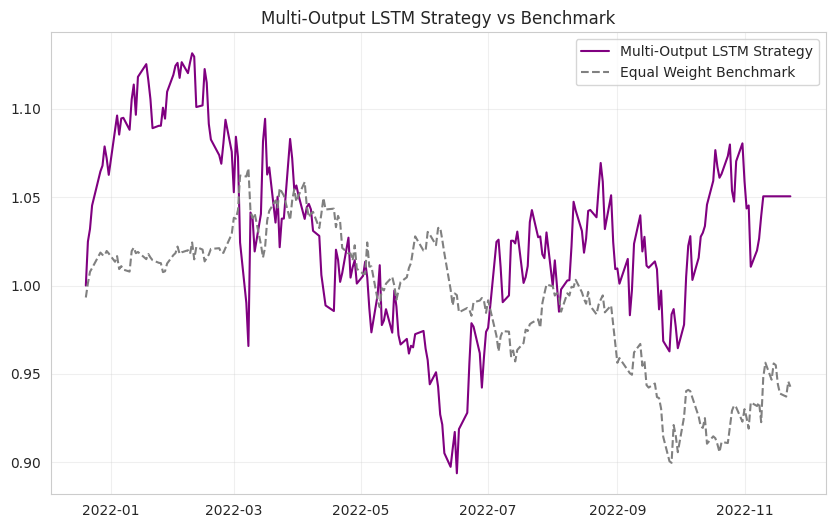

In [38]:

# ==============================================================================
# 3e. Trading Strategy & Backtest
# ==============================================================================
print("\n" + "="*60)
print("STEP 3: TRADING STRATEGY BACKTEST")
print("="*60)

# Reuse the logic from Step 2d/2e but applied to the multi-output predictions
def backtest_multi_output(predictions_df, returns_data, horizon=25):
    # 1. Identify Rebalancing Dates
    rebalance_dates = predictions_df.index[::horizon]

    portfolio_weights = pd.DataFrame(0.0, index=predictions_df.index, columns=tickers)

    # 2. Generate Signals (Long Top 2, Short Bottom 2)
    for i in range(len(rebalance_dates)-1):
        date = rebalance_dates[i]
        next_date = rebalance_dates[i+1]

        # Get predictions for this day
        day_preds = predictions_df.loc[date].sort_values(ascending=False)

        long_assets = day_preds.index[:2]   # Top 2
        short_assets = day_preds.index[-2:] # Bottom 2

        # Assign weights
        w_long = 0.5   # 50% each
        w_short = -0.5 # -50% each

        # Set weights for the period [date, next_date)
        mask = (portfolio_weights.index >= date) & (portfolio_weights.index < next_date)
        for asset in long_assets:
            portfolio_weights.loc[mask, asset] = w_long
        for asset in short_assets:
            portfolio_weights.loc[mask, asset] = w_short

    # 3. Calculate Strategy Returns
    # Shift weights by 1 day because weights determined at close of 'date' apply to 'date+1' returns
    aligned_weights = portfolio_weights.shift(1).fillna(0)

    # Extract relevant returns (matched by index)
    aligned_returns = returns_data.loc[aligned_weights.index]

    # Daily portfolio return
    strat_ret = (aligned_weights * aligned_returns).sum(axis=1)

    return strat_ret

# Run Backtest
strategy_returns_multi = backtest_multi_output(pred_df_multi, returns)
cumulative_strategy = (1 + strategy_returns_multi).cumprod()

# Benchmark (Equal Weight)
benchmark_returns = returns.loc[strategy_returns_multi.index].mean(axis=1)
cumulative_benchmark = (1 + benchmark_returns).cumprod()

# Comparison Metrics
total_ret_strat = cumulative_strategy.iloc[-1] - 1
total_ret_bench = cumulative_benchmark.iloc[-1] - 1
sharpe_strat = (strategy_returns_multi.mean() / strategy_returns_multi.std()) * np.sqrt(252)

print(f"Strategy Total Return: {total_ret_strat:.2%}")
print(f"Benchmark Total Return: {total_ret_bench:.2%}")
print(f"Strategy Sharpe Ratio: {sharpe_strat:.2f}")

# Plot
plt.figure(figsize=(10, 6))
plt.plot(cumulative_strategy, label='Multi-Output LSTM Strategy', color='purple')
plt.plot(cumulative_benchmark, label='Equal Weight Benchmark', color='gray', linestyle='--')
plt.title('Multi-Output LSTM Strategy vs Benchmark')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()